<a href="https://colab.research.google.com/github/gauravkapase45/CIE_2_Activity_1_Multiple_Linear_Regression/blob/main/CIE_2_Activity_1_Crop_Yield_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.api import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3


In [2]:
dataset_url = "https://raw.githubusercontent.com/kdeeey/cropai/main/data/yield_df.csv"
try:
    df = pd.read_csv(dataset_url)
    print("Dataset downloaded successfully.")
except Exception as error:
    print("Automatic download failed. Upload yield_df.csv.")
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))

print("Dataset shape:", df.shape)
display(df.head())

Dataset downloaded successfully.
Dataset shape: (28242, 8)


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [3]:
print("Columns:", df.columns.tolist())
df.info()
print("\\nMissing values:")
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Columns: ['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  object 
 2   Item                           28242 non-null  object 
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.7+ MB
\nMissing values:


,0
Unnamed: 0,0
Area,0
Item,0
Year,0
hg/ha_yield,0
average_rain_fall_mm_per_year,0
pesticides_tonnes,0
avg_temp,0


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,28242.0,14120.500000,8152.907488,0.00,7060.2500,14120.50,21180.75,28241.00
Year,28242.0,2001.544296,7.051905,1990.00,1995.0000,2001.00,2008.00,2013.00
hg/ha_yield,28242.0,77053.332094,84956.612897,50.00,19919.2500,38295.00,104676.75,501412.00
average_rain_fall_mm_per_year,28242.0,1149.055980,709.812150,51.00,593.0000,1083.00,1668.00,3240.00
pesticides_tonnes,28242.0,37076.909344,59958.784665,0.04,1702.0000,17529.44,48687.88,367778.00
avg_temp,28242.0,20.542627,6.312051,1.30,16.7025,21.51,26.00,30.65


In [4]:
features = ["Year", "average_rain_fall_mm_per_year", "pesticides_tonnes", "avg_temp"]
target = "hg/ha_yield"
required = features + [target]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Required columns missing: {missing}. Upload the correct yield_df.csv.")

data = df[required].copy()
for col in required:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates().reset_index(drop=True)
print("Rows after cleaning:", len(data))
print("Missing values remaining:", data.isnull().sum().sum())
display(data.head())

Rows after cleaning: 25919
Missing values remaining: 0


,Year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,hg/ha_yield
0,1990,1485.0,121.0,16.37,36613
1,1990,1485.0,121.0,16.37,66667
2,1990,1485.0,121.0,16.37,23333
3,1990,1485.0,121.0,16.37,12500
4,1990,1485.0,121.0,16.37,7000


In [5]:
X = data[features]
y = data[target]
print("Input features:", features)
print("Target:", target, "(hg/ha)")
print("Number of records:", len(data))

Input features: ['Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
Target: hg/ha_yield (hg/ha)
Number of records: 25919


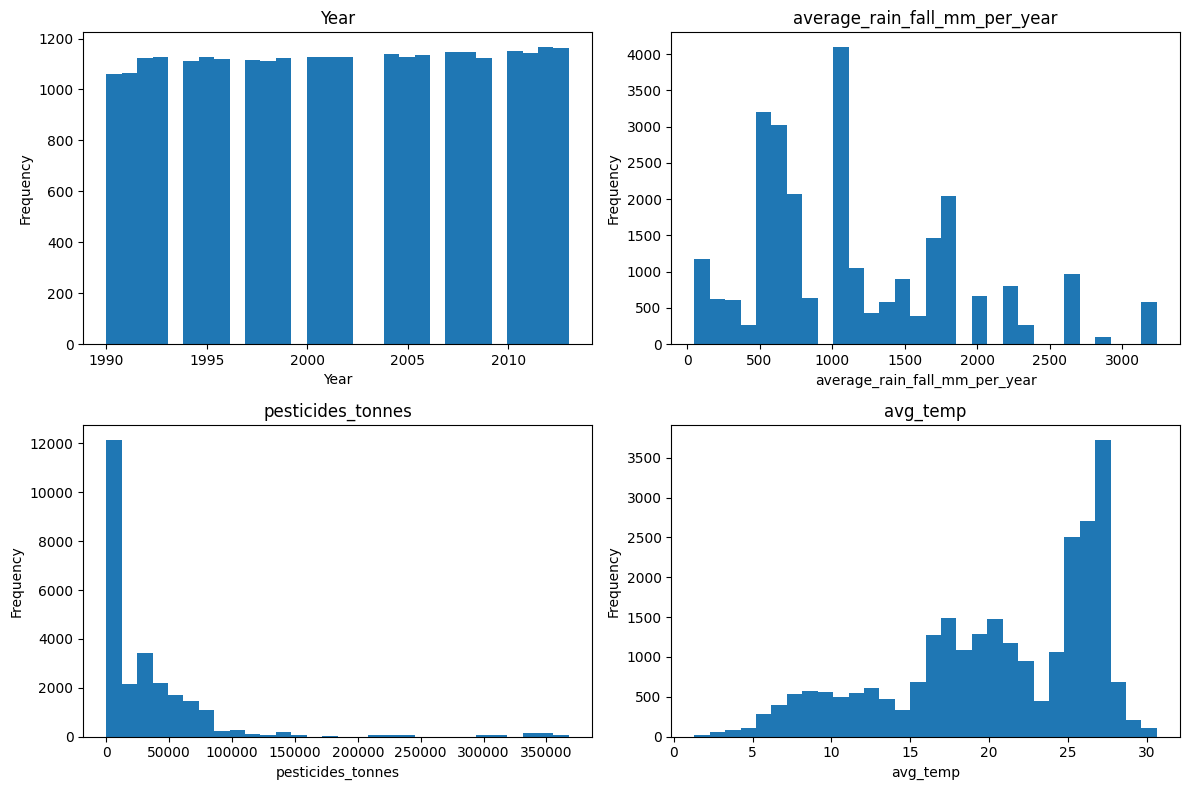

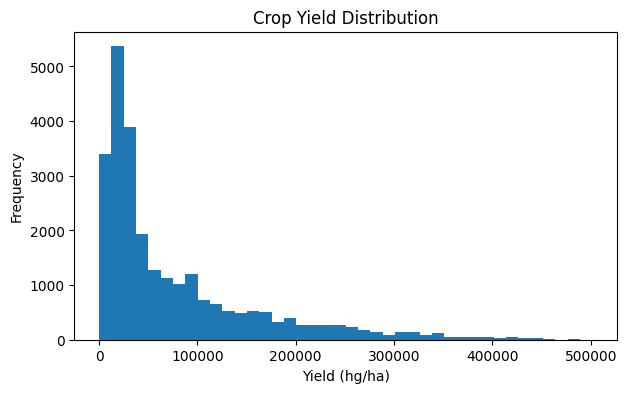

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), features):
    ax.hist(data[col], bins=30)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(y, bins=40)
plt.title("Crop Yield Distribution")
plt.xlabel("Yield (hg/ha)")
plt.ylabel("Frequency")
plt.show()

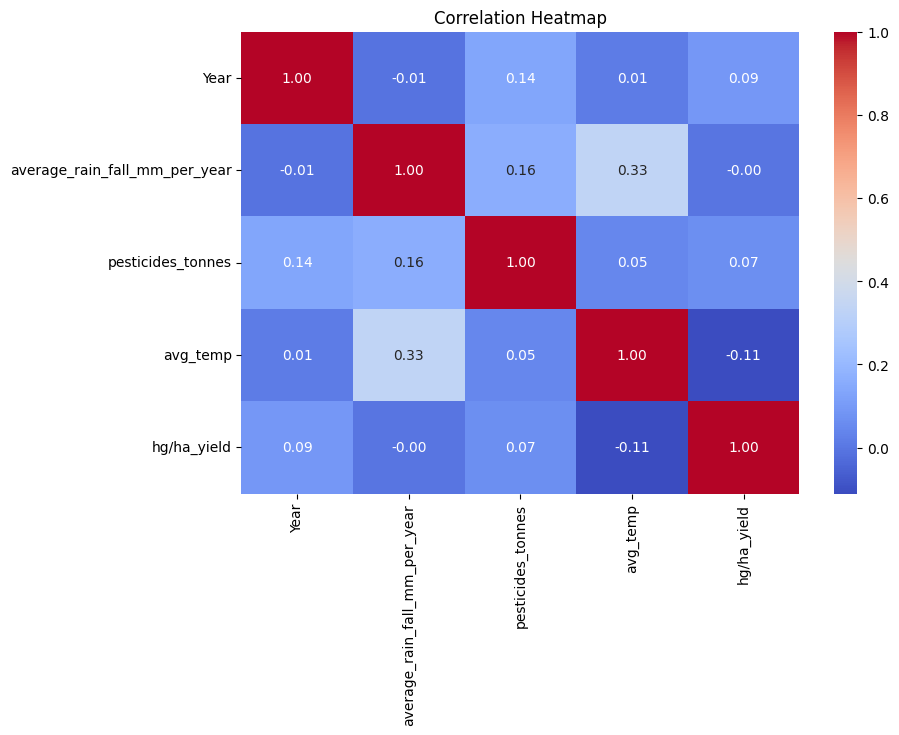

,hg/ha_yield
hg/ha_yield,1.000000
Year,0.091300
pesticides_tonnes,0.065351
average_rain_fall_mm_per_year,-0.003952
avg_temp,-0.110266


In [7]:
corr = data[features + [target]].corr()
plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()
display(corr[[target]].sort_values(target, ascending=False))

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 20735
Testing rows: 5184


In [9]:
manual_features = ["average_rain_fall_mm_per_year", "avg_temp"]
sample = data[manual_features + [target]].head(10)
Xm = sample[manual_features].to_numpy(dtype=float)
ym = sample[target].to_numpy(dtype=float)
X_design = np.column_stack([np.ones(len(Xm)), Xm])
X_transpose = X_design.T
XTX = X_transpose @ X_design
XTy = X_transpose @ ym

print("Manual calculation sample:")
display(sample)
print("Design matrix X:")
print(X_design)
print("X transpose:")
print(X_transpose)
print("XTX:")
print(XTX)
print("XTy:")
print(XTy)

beta = np.linalg.pinv(XTX) @ XTy
print("Solved coefficients [Intercept, Rainfall, Temperature]:")
print(beta)
manual_pred = X_design @ beta
display(pd.DataFrame({"Actual Yield": ym, "Predicted Yield": manual_pred,
                      "Residual": ym - manual_pred}))

Manual calculation sample:


,average_rain_fall_mm_per_year,avg_temp,hg/ha_yield
0,1485.0,16.37,36613
1,1485.0,16.37,66667
2,1485.0,16.37,23333
3,1485.0,16.37,12500
4,1485.0,16.37,7000
5,1485.0,16.37,30197
6,1485.0,15.36,29068
7,1485.0,15.36,77818
8,1485.0,15.36,28538
9,1485.0,15.36,6667


Design matrix X:
[[1.000e+00 1.485e+03 1.637e+01]
 [1.000e+00 1.485e+03 1.637e+01]
 [1.000e+00 1.485e+03 1.637e+01]
 [1.000e+00 1.485e+03 1.637e+01]
 [1.000e+00 1.485e+03 1.637e+01]
 [1.000e+00 1.485e+03 1.637e+01]
 [1.000e+00 1.485e+03 1.536e+01]
 [1.000e+00 1.485e+03 1.536e+01]
 [1.000e+00 1.485e+03 1.536e+01]
 [1.000e+00 1.485e+03 1.536e+01]]
X transpose:
[[1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00 1.000e+00
  1.000e+00 1.000e+00 1.000e+00]
 [1.485e+03 1.485e+03 1.485e+03 1.485e+03 1.485e+03 1.485e+03 1.485e+03
  1.485e+03 1.485e+03 1.485e+03]
 [1.637e+01 1.637e+01 1.637e+01 1.637e+01 1.637e+01 1.637e+01 1.536e+01
  1.536e+01 1.536e+01 1.536e+01]]
XTX:
[[1.0000000e+01 1.4850000e+04 1.5966000e+02]
 [1.4850000e+04 2.2052250e+07 2.3709510e+05]
 [1.5966000e+02 2.3709510e+05 2.5515798e+03]]
XTy:
[3.18401000e+05 4.72825485e+08 5.06871246e+06]
Solved coefficients [Intercept, Rainfall, Temperature]:
[ 5.84362627e-02  8.67778501e+01 -6.07698020e+03]


,Actual Yield,Predicted Yield,Residual
0,36613.0,29385.00,7228.00
1,66667.0,29385.00,37282.00
2,23333.0,29385.00,-6052.00
3,12500.0,29385.00,-16885.00
4,7000.0,29385.00,-22385.00
5,30197.0,29385.00,812.00
6,29068.0,35522.75,-6454.75
7,77818.0,35522.75,42295.25
8,28538.0,35522.75,-6984.75
9,6667.0,35522.75,-28855.75


In [10]:
single_feature = ["average_rain_fall_mm_per_year"]
single_model = LinearRegression()
single_model.fit(X_train[single_feature], y_train)
single_train_pred = single_model.predict(X_train[single_feature])
single_test_pred = single_model.predict(X_test[single_feature])

print("Intercept:", single_model.intercept_)
print("Rainfall coefficient:", single_model.coef_[0])
print(f"Equation: Yield = {single_model.intercept_:.4f} + ({single_model.coef_[0]:.4f} × Rainfall)")

Intercept: 77978.25235314644
Rainfall coefficient: -0.7513487988987749
Equation: Yield = 77978.2524 + (-0.7513 × Rainfall)


In [11]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multi_train_pred = multiple_model.predict(X_train)
multi_test_pred = multiple_model.predict(X_test)

print("Intercept:", multiple_model.intercept_)
coef_table = pd.DataFrame({"Feature": features, "Coefficient": multiple_model.coef_})
display(coef_table)

equation = f"Yield = {multiple_model.intercept_:.4f}"
for name, value in zip(features, multiple_model.coef_):
    equation += f" + ({value:.4f} × {name})"
print("Fitted equation:")
print(equation)

Intercept: -2090434.6852344156


,Feature,Coefficient
0,Year,1096.139319
1,average_rain_fall_mm_per_year,3.111956
2,pesticides_tonnes,0.079565
3,avg_temp,-1605.773076


Fitted equation:
Yield = -2090434.6852 + (1096.1393 × Year) + (3.1120 × average_rain_fall_mm_per_year) + (0.0796 × pesticides_tonnes) + (-1605.7731 × avg_temp)


In [12]:
for feature, value in zip(features, multiple_model.coef_):
    direction = "increase" if value > 0 else "decrease"
    print(f"A one-unit increase in {feature} is associated with an estimated {direction} of {abs(value):.4f} hg/ha in predicted yield, holding the other included features constant.")
print("These are statistical associations, not proof of cause and effect.")

A one-unit increase in Year is associated with an estimated increase of 1096.1393 hg/ha in predicted yield, holding the other included features constant.
A one-unit increase in average_rain_fall_mm_per_year is associated with an estimated increase of 3.1120 hg/ha in predicted yield, holding the other included features constant.
A one-unit increase in pesticides_tonnes is associated with an estimated increase of 0.0796 hg/ha in predicted yield, holding the other included features constant.
A one-unit increase in avg_temp is associated with an estimated decrease of 1605.7731 hg/ha in predicted yield, holding the other included features constant.
These are statistical associations, not proof of cause and effect.


In [13]:
def regression_metrics(actual, predicted, p):
    n = len(actual)
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    adj_r2 = 1 - (1-r2)*(n-1)/(n-p-1) if n > p+1 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adjusted R2": adj_r2}

single_metrics = regression_metrics(y_test, single_test_pred, 1)
multi_metrics = regression_metrics(y_test, multi_test_pred, len(features))
comparison = pd.DataFrame([single_metrics, multi_metrics],
                          index=["Single-feature model", "Multiple-feature model"])
display(comparison.round(4))

,MAE,MSE,RMSE,R2,Adjusted R2
Single-feature model,63526.2578,6.982124e+09,83559.1022,-0.0002,-0.0004
Multiple-feature model,63106.5967,6.820805e+09,82588.1659,0.0229,0.0222


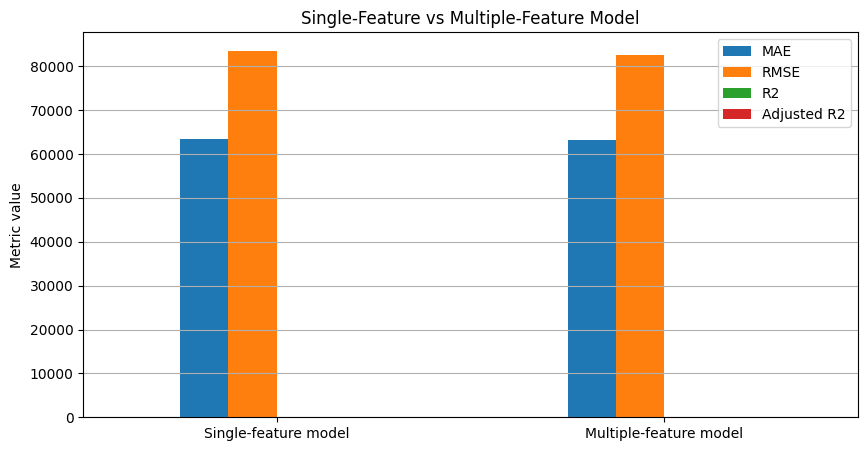

Use the test-set comparison to decide whether the additional features justify the extra complexity.


In [14]:
comparison[["MAE", "RMSE", "R2", "Adjusted R2"]].plot(kind="bar", figsize=(10, 5))
plt.title("Single-Feature vs Multiple-Feature Model")
plt.ylabel("Metric value")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()
print("Use the test-set comparison to decide whether the additional features justify the extra complexity.")

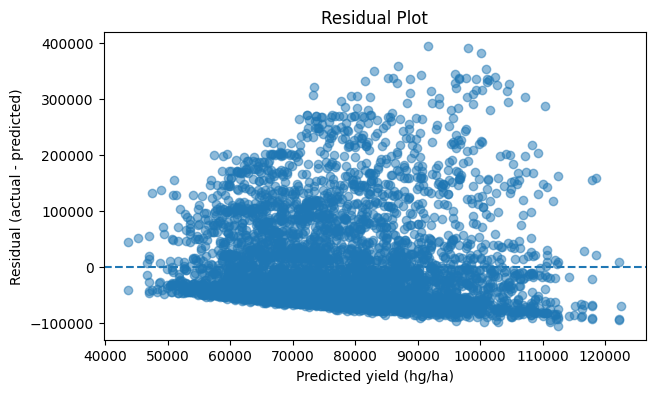

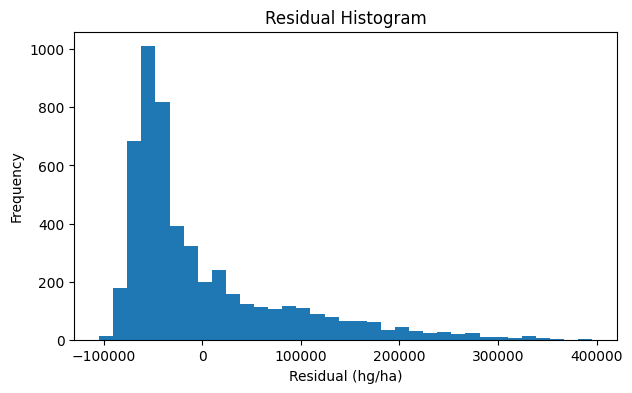

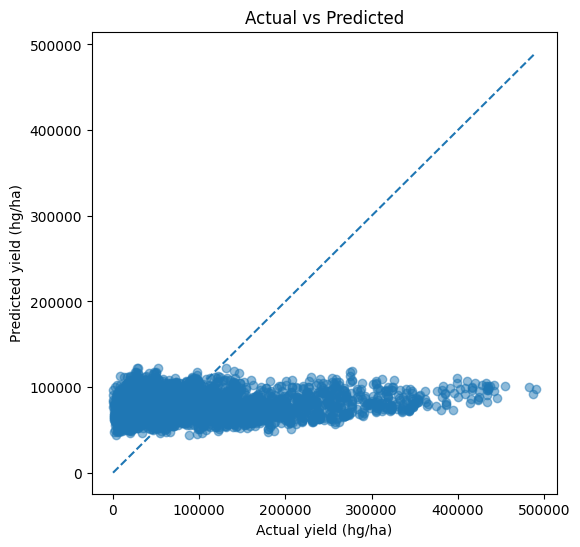

In [15]:
residuals = y_test - multi_test_pred

plt.figure(figsize=(7, 4))
plt.scatter(multi_test_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted yield (hg/ha)")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual Plot")
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=35)
plt.xlabel("Residual (hg/ha)")
plt.ylabel("Frequency")
plt.title("Residual Histogram")
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_test, multi_test_pred, alpha=0.5)
lo = min(y_test.min(), multi_test_pred.min())
hi = max(y_test.max(), multi_test_pred.max())
plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Actual yield (hg/ha)")
plt.ylabel("Predicted yield (hg/ha)")
plt.title("Actual vs Predicted")
plt.show()

In [16]:
X_vif = add_constant(X_train.astype(float), has_constant="add")
vif = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
})
display(vif)

,Feature,VIF
0,const,1.000000
1,Year,1.019807
2,average_rain_fall_mm_per_year,1.151322
3,pesticides_tonnes,1.046049
4,avg_temp,1.123070


In [17]:
new_example = pd.DataFrame([{
    feature: X_train[feature].median() for feature in features
}])
new_prediction = multiple_model.predict(new_example)[0]
print("New example:")
display(new_example)
print("Predicted crop yield:", round(new_prediction, 2), "hg/ha")
print("Approximate yield:", round(new_prediction / 10000, 4), "tonnes/ha")

New example:


,Year,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,2001.0,1083.0,15373.0,21.31


Predicted crop yield: 73314.46 hg/ha
Approximate yield: 7.3314 tonnes/ha
